# 06　AM / FM / ASK / PSK / QAM：发送与接收

`00_init` 之后（断电重启的话，本册第 3 节会自己拉时钟、下位流），本册用**同一条**硬件路径
把五个调制案例送出去再抓回来：

```
已知比特 / 消息 → 映射 / 成型 → DMA(MM2S) 单次突发 → 立即 DMA(S2MM) 整包抓回 → .npz
```

本册只负责"发"和"抓"，**不做解调**。解调在 `07_mod_demod`，判据在 `08_mod_verify`。
三本之间用 `.npz` 传递，任意一本都能单独重跑。

| 案例 | 类型 | 每符号比特 | 载荷 | 帧结构 / 时长 | 关键参数 |
|---|---|---|---|---|---|
| ASK4 | 数字 | 2（4 电平 PAM） | 1024 bit × 9 帧 | ZC 前导 64 + 载荷 512 + 保护 16 | 峰值 −12 dBFS |
| 8PSK | 数字 | 3 | 1536 bit × 9 帧 | 同上，载荷 512 | Gray 相位映射 |
| 16QAM | 数字 | 4 | 1024 bit × 9 帧 | 同上，载荷 256 | I/Q 各自 Gray |
| AM | 模拟 | — | 单音 0.5 MHz | 连续 2.048 ms | μ=0.8，IF 8 MHz |
| FM | 模拟 | — | 单音 0.5 MHz | 连续 2.048 ms | Δf=2 MHz（β=4），IF 8 MHz |

> **为什么五个案例共用一套代码。** 数字三案都沿用 QPSK 的帧结构：ZC 前导只做定时、频偏和
> 复增益估计，与载荷星座无关，所以换星座只换 `Const` 这一层。模拟两案不加前导（连续发送），
> 接收端按**已知测试消息**对齐 —— 这是验证场景，不是盲解调，报告里会写清楚。

## 1　导入与参数

模块在 `/home/xilinx/modulation/`，与命令行版 `run_mod_test.py` 是**同一份代码**；
`mod_dsp` 只依赖 QPSK 那边已经在板上验证过的 `qpsk_dsp`。

In [1]:
import os
import sys

MOD_DIR = "/home/xilinx/modulation"
NB_DIR = "/home/xilinx/jupyter_notebooks/modulation"
QPSK_DIR = "/home/xilinx/qpsk"
for _p in (MOD_DIR, QPSK_DIR):
    if os.path.isdir(_p) and _p not in sys.path:
        sys.path.insert(0, _p)

SAVE_DIR = NB_DIR if os.path.isdir(NB_DIR) else MOD_DIR


def npz_path(name):
    """本文件夹优先，模块目录兜底。"""
    for d in (NB_DIR, MOD_DIR):
        p = os.path.join(d, name)
        if os.path.exists(p):
            return p
    return os.path.join(SAVE_DIR, name)

import time

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

import mod_dsp as M
import mod_cases as C
import qpsk_dsp as D

# font.family 列表触发逐字形回退（mpl≥3.6）：拉丁取自 DejaVu，中文取本机
# 已有的 CJK 字体（板上 Droid Sans Fallback / Windows 雅黑）。只列**已安装**的
# 名字，否则 matplotlib 会为每个字形打一行 findfont 警告（实测上千行）。
import matplotlib.font_manager as _fm
_avail = {f.name for f in _fm.fontManager.ttflist}
_fam = [n for n in ("DejaVu Sans", "Microsoft YaHei", "Noto Sans CJK SC",
                    "WenQuanYi Zen Hei", "Droid Sans Fallback") if n in _avail]
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
    "axes.titlesize": 10, "legend.fontsize": 8,
    "font.family": _fam or ["DejaVu Sans"],
    "axes.unicode_minus": False,
})

print("mod_dsp  :", M.__file__)
print("qpsk_dsp :", D.__file__)
print("SPS = %d → 符号率 %.1f MBaud（字率 256 MHz）"
      % (M.SPS, 256.0 / M.SPS))
print("保存目录 :", SAVE_DIR)

mod_dsp  : /home/xilinx/modulation/mod_dsp.py
qpsk_dsp : /home/xilinx/qpsk/qpsk_dsp.py
SPS = 8 → 符号率 32.0 MBaud（字率 256 MHz）
保存目录 : /home/xilinx/jupyter_notebooks/modulation


## 2　生成五个案例的基带

数字案例的组帧：`[64 符号 ZC 前导][载荷][16 符号零保护]`，RRC 成型（α=0.35，span=6），
9 帧首尾相接，前后各留 64 个符号的静默。

模拟案例：AM 是 DSB-LC，$s(t)=[1+\mu\cos(2\pi f_m t)]e^{j2\pi f_c t}$；
FM 是 $s(t)=\exp\left(j[2\pi f_c t+2\pi\Delta f\int m\,dt]\right)$。两者都放在
**基带 8 MHz** 的 IF 上 —— 送到 RF 后是 NCO 1000 MHz ± 8 MHz。

归一化一律按**峰值** 0.4（≈ −12 dBFS）：ASK/16QAM 的峰均比随图样变化，按 RMS 归一
会让某些图样削顶。

In [2]:
built = {}

for spec in C.DIGITAL_CASES:
    const, frames, fsyms, bb, lead, spf = C.build_digital(spec)
    built[spec["name"]] = dict(spec=spec, kind="digital", const=const,
                               frames=frames, fsyms=fsyms, bb=bb,
                               lead=lead, spf=spf, words=D.to_words(bb))

for spec in C.ANALOG_CASES:
    bb, msg, meta = C.build_analog(spec)
    built[spec["name"]] = dict(spec=spec, kind="analog", msg=msg,
                               meta=meta, bb=bb, words=D.to_words(bb))

print("%-6s %-4s %9s %10s %8s %8s  %s"
      % ("案例", "类型", "样点", "时长 ms", "峰值LSB", "PAPR dB", "说明"))
print("-" * 96)
for name, b in built.items():
    bb = b["bb"]
    act = bb[np.abs(bb) > 1e-12]
    peak = int(np.max(np.abs(bb)) * 32767)
    papr = 20 * np.log10(np.max(np.abs(act)) / np.sqrt(np.mean(np.abs(act) ** 2)))
    if b["kind"] == "digital":
        note = "%d 帧 × (%d 载荷 + %d 前导 + %d 保护 符号)" % (
            len(b["frames"]), len(b["fsyms"][0]), M.N_PRE, M.GUARD_SYM)
    else:
        m = b["meta"]
        if name == "AM":
            note = "μ=%.1f，消息 %.2f MHz @ IF %.1f MHz" % (
                m["mu"], m["fm"] / 1e6, m["fc"] / 1e6)
        else:
            note = "Δf=%.1f MHz（β=%.1f），消息 %.2f MHz @ IF %.1f MHz" % (
                m["df"] / 1e6, m["beta"], m["fm"] / 1e6, m["fc"] / 1e6)
    print("%-6s %-4s %9d %10.3f %8d %8.2f  %s"
          % (name, "数字" if b["kind"] == "digital" else "模拟",
             len(bb), len(bb) / 256e6 * 1e3, peak, papr, note))

print()
print("整数幅度上限 %d，最大峰值 %d → 削顶样点 %d（必须为 0）"
      % (32767, int(max(np.max(np.abs(b["bb"])) for b in built.values()) * 32767),
         sum(int(np.sum(np.abs(b["bb"]) * 32767 > 32767)) for b in built.values())))

案例     类型          样点      时长 ms    峰值LSB  PAPR dB  说明
------------------------------------------------------------------------------------------------
ASK4   数字       43648      0.170    13106     6.18  9 帧 × (512 载荷 + 64 前导 + 16 保护 符号)
8PSK   数字       43648      0.170    13106     3.46  9 帧 × (512 载荷 + 64 前导 + 16 保护 符号)
16QAM  数字       25216      0.098    13106     5.79  9 帧 × (256 载荷 + 64 前导 + 16 保护 符号)
AM     模拟      532480      2.080    13106     3.90  μ=0.8，消息 0.50 MHz @ IF 8.0 MHz
FM     模拟      532480      2.080    13106     0.00  Δf=2.0 MHz（β=4.0），消息 0.50 MHz @ IF 8.0 MHz



整数幅度上限 32767，最大峰值 13106 → 削顶样点 0（必须为 0）


**应该看到**：ASK4 / 8PSK / 16QAM 的发射波形都是约 0.17 ms 的短突发（9 帧），
AM / FM 是 2.1 ms 的连续波形；峰值都在 13107 LSB（0.4×32767）附近，削顶为 0。

上图：三个数字星座、AM 的基带波形、FM 的瞬时频率、以及 AM/FM 的发射谱。

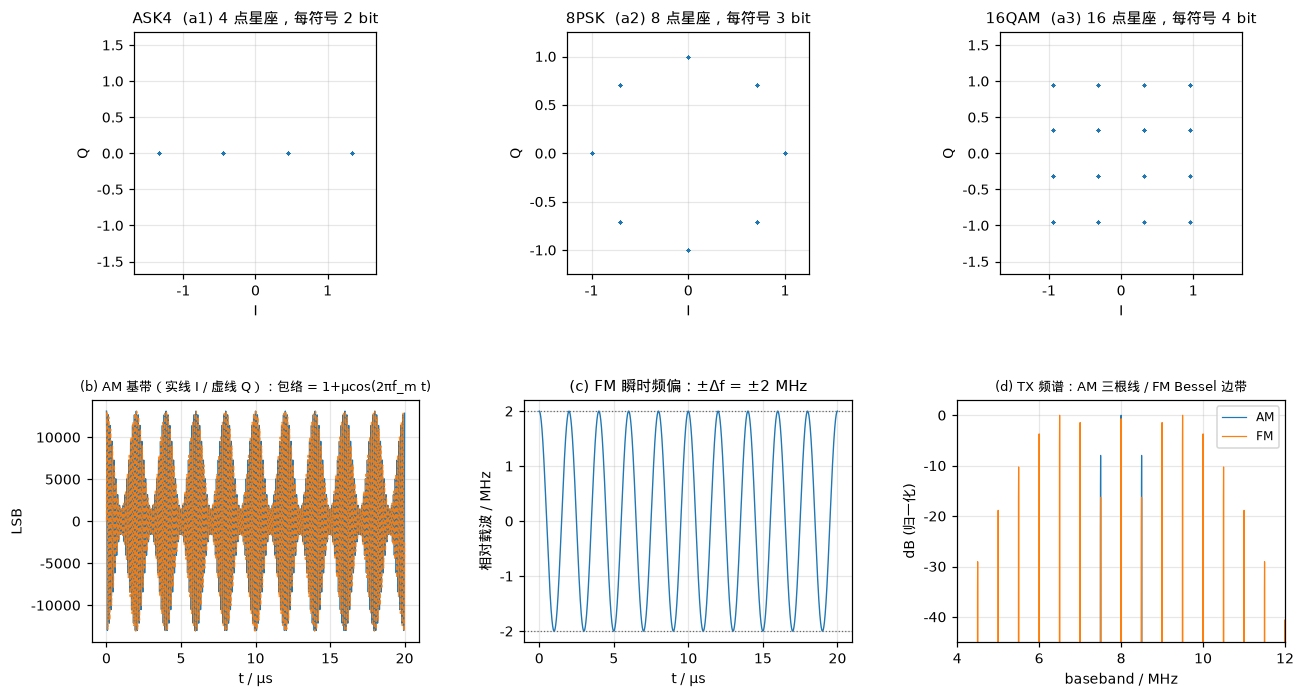

In [3]:
fig = plt.figure(figsize=(14, 7.2))
gs = fig.add_gridspec(2, 3, hspace=0.52, wspace=0.32)

for col, name in enumerate(("ASK4", "8PSK", "16QAM")):
    b = built[name]
    sy = np.concatenate(b["fsyms"])
    ax = fig.add_subplot(gs[0, col])
    ax.plot(sy.real, sy.imag, ".", ms=2.2, alpha=0.45)
    lim = 1.25 * max(1.0, float(np.max(np.abs(sy))))
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_xlabel("I"); ax.set_ylabel("Q")
    ax.set_title("%s  (a%d) %d 点星座，每符号 %d bit"
                 % (name, col + 1, b["const"].M,
                    b["const"].k * (2 if b["const"].scheme == "qam" else 1)))

FSW = 256e6
b = built["AM"]; bb = b["bb"]; lead = b["meta"]["lead"]
n = int(20e-6 * FSW); t = np.arange(n) / FSW * 1e6
ax = fig.add_subplot(gs[1, 0])
ax.plot(t, bb[lead:lead + n].real * 32767, lw=0.9, label="I")
ax.plot(t, bb[lead:lead + n].imag * 32767, lw=0.8, ls="--", alpha=0.9, label="Q")
ax.set_xlabel("t / µs"); ax.set_ylabel("LSB")
ax.set_title("(b) AM 基带（实线 I / 虚线 Q）：包络 = 1+μcos(2πf_m t)",
             fontsize=8.5)

b = built["FM"]; bb = b["bb"]; lead = b["meta"]["lead"]
ph = np.unwrap(np.angle(bb[lead:lead + n]))
inst = np.diff(ph) * FSW / (2 * np.pi) - b["meta"]["fc"]   # 扣掉 IF 载波
ax = fig.add_subplot(gs[1, 1])
ax.plot(t[:-1], inst / 1e6, lw=0.9)
ax.axhline(b["meta"]["df"] / 1e6, color="0.4", ls=":", lw=0.8)
ax.axhline(-b["meta"]["df"] / 1e6, color="0.4", ls=":", lw=0.8)
ax.set_xlabel("t / µs"); ax.set_ylabel("相对载波 / MHz")
ax.set_title("(c) FM 瞬时频偏：±Δf = ±2 MHz")

ax = fig.add_subplot(gs[1, 2])
for name in ("AM", "FM"):
    b = built[name]; bb = b["bb"]; lead = b["meta"]["lead"]
    seg = bb[lead:lead + 65536] * np.hanning(65536)
    X = np.fft.fftshift(np.fft.fft(seg))
    f = np.fft.fftshift(np.fft.fftfreq(len(seg), 1 / FSW))
    dB = 20 * np.log10(np.abs(X) + 1e-12)
    ax.plot(f / 1e6, dB - dB.max(), lw=0.8, label=name)
ax.set_xlim(4, 12); ax.set_ylim(-45, 3)
ax.set_xlabel("baseband / MHz"); ax.set_ylabel("dB (归一化)")
ax.set_title("(d) TX 频谱：AM 三根线 / FM Bessel 边带", fontsize=8.5)
ax.legend(loc="upper right")

plt.show()

## 3　环境就绪：时钟、位流、RFDC、DMA

这一步与 `00_init` + `01_qpsk_tx_rx` 第 4 节做的是同一件事，直接复用：

| 动作 | 函数 | 说明 |
|---|---|---|
| LMK 256 MHz + SYSREF | `qpsk_init.ensure_clock()` | 已锁定时 ~0.2 s 返回，不重写寄存器 |
| 位流 `v106/soc.bit` | `run_test.open_clean_loopback()` | PL 里已是 v106 就只解析 hwh，不重下 |
| RFDC 4096 MSPS + NCO 1000 MHz | 同上 | 同进程内已 init 过就不再 StartUp |
| 环回自检 | 同上 | 打一发 QPSK 探针，波峰因数 < 2.5 才算干净 |

**为什么用 QPSK 探针而不是本册的案例**：QPSK 那套自检已经在板上验证过，波峰因数阈值
（干净 ≈1.6，ADC 只回 I 通道时 ≥3.4）有明确实测依据。案例本身只用于测指标。

In [4]:
import qpsk_init as QI
import run_test as R

clk = QI.ensure_clock()

probe = C.build_payload_set(1024, 9, 300)
h_q = D.rrc_filter(D.SPS)
probe_bb, _, _ = D.build_burst([b for _t, b in probe], h_q, D.SPS, peak=C.PEAK)

t_open = time.time()
lb, n_try, cf = R.open_clean_loopback(D.to_words(probe_bb), len(probe_bb))
print()
print("环回就绪：自检 %d 次，波峰因数 %.2f（阈值 %.1f），耗时 %.1f s"
      % (n_try, cf, R.CF_CLEAN, time.time() - t_open))
print("字率 %.3f MHz，RF %.1f MSPS"
      % (lb.fs_word / 1e6, lb.fs_rf))
st = lb.status()
for k in ("DAC", "ADC"):
    v = st[k]
    print("%s0 : enabled=%s  state=0x%X  PLL=%s"
          % (k, v.get("enabled"), v.get("state", 0), v.get("pll")))

  读回窗口自检通过（3 字节传输，rx[2] = 数据字节）

=== 配置四线 SPI readback ===
  SPI_LOCK 解锁 (R0x1FFD/R0x1FFE=0x00, R0x1FFF=0x53)
  R0x000 = 0x10 (SPI_3WIRE_DIS=1)
  R0x15F 无条件写回 0x13（写前读到 0x13，脏状态下该读数不可信）
  R0x16E = 0x3B (PLL2_LD_MUX=7 readback, TYPE=3 推挽)
  读回可信度检查通过（R0x171=0xAA / R0x172=0x02）
→ PLL2 已锁定、SYSREF 连续输出，跳过写表
  LMK 现状: 读回可信=True  PLL1 LD=0(0x00)  PLL2 LD=1(0x06)  SYSREF MUX=3
  [PASS] LMK 读回可信                                 R0x171=0xAA / R0x172=0x02
  [PASS] LMK PLL2 锁定（RFDC 时钟源）                 R0x183=0x06
  [PASS] SYSREF 连续输出（MUX=3）                     R0x139 MUX=3
  PLL1 LD=0（本板 PLL1 空载，LD=0 正常，不是故障）

 2　时钟
  结果  项目                                         实测 / 说明
  ----------------------------------------------------------------------------
  PASS  LMK 读回可信                                 R0x171=0xAA / R0x172=0x02
  PASS  LMK PLL2 锁定（RFDC 时钟源）                 R0x183=0x06
  PASS  SYSREF 连续输出（MUX=3）                     R0x139 MUX=3
  --------------------------------------------------------

  overlay 承接 1059 ms，5 个 IP
  DAC0 NCO 已是 1000.000 MHz，沿用
  ADC0 NCO 已是 1000.000 MHz，沿用


  环回自检  0（首次建立）：波峰因数 1.66  OK

环回就绪：自检 1 次，波峰因数 1.66（阈值 2.5），耗时 2.4 s
字率 256.000 MHz，RF 4096.0 MSPS
DAC0 : enabled=True  state=0xF  PLL=1
ADC0 : enabled=True  state=0xF  PLL=1


**应该看到**：`PLL2 LD=1`、`SYSREF MUX=3`、`波峰因数 < 2.5`、`DAC0 state=0xF`、`ADC0 enabled=1`。

**不对怎么查**：

| 现象 | 处置 |
|---|---|
| `PLL2 LD=0` | `QI.ensure_clock(force=True)` 重写 LMK 表 |
| 波峰因数 ≥ 3 | ADC 只回了 I 通道；`open_clean_loopback` 会自动 `rf_reinit()`，连续失败再查环回线 |
| `DAC state≠0xF` | 先回 `00_init` 第 4 节等 FIFO 起转 |

## 4　逐案例收发并落盘

时序与 `02` 一致：**先挂接收、再启动发送**，这样突发完整落在 16.38 ms 的接收窗里。
一次 `lb.loop(words)` 同时完成 MM2S 发送与 S2MM 整包接收。

落盘只存突发前后各 64k 点的一段（整包 4.19 M 字里 98% 是静默），存的是**原始字**，
`07` 可以据此把接收机每一步重算一遍。

In [5]:
for name in ("ASK4", "8PSK", "16QAM"):
    b = built[name]
    spec = b["spec"]

    t0 = time.time()
    G = lb.loop(b["words"])
    dt = time.time() - t0

    x = D.from_words(G["w"])
    n = int(G["n"])
    x = x[:n] if n else x
    a, e = D.find_active(x)

    p = os.path.join(SAVE_DIR, "mod_06_%s.npz" % name)
    C.save_capture(p, name, x, len(b["bb"]), lb.fs_word,
                   extra=dict(case_kind="digital", scheme=spec["scheme"],
                              k=spec["k"], n_bits=spec["n_bits"],
                              frames=spec["frames"], seed=C.SEED))

    built[name]["x"] = x
    print("%-6s 收 %7d 字 (%.2f ms)  活跃区 [%d,%d)  TX %s  GAP %.0f us  "
          "墙钟 %.0f ms  存 %.2f MB"
          % (name, n, n / lb.fs_word * 1e3, a, e,
             "完成" if G["tx_ok"] else "未完成", G["gap_us"], dt * 1e3,
             os.path.getsize(p) / 1e6))

ASK4   收 4194299 字 (16.38 ms)  活跃区 [20480,65536)  TX 完成  GAP 81 us  墙钟 262 ms  存 0.29 MB


8PSK   收 4194299 字 (16.38 ms)  活跃区 [15360,60416)  TX 完成  GAP 63 us  墙钟 280 ms  存 0.29 MB


16QAM  收 4194299 字 (16.38 ms)  活跃区 [14336,41984)  TX 完成  GAP 60 us  墙钟 275 ms  存 0.23 MB


In [6]:
for name in ("AM", "FM"):
    b = built[name]
    spec = b["spec"]

    t0 = time.time()
    G = lb.loop(b["words"])
    dt = time.time() - t0

    x = D.from_words(G["w"])
    n = int(G["n"])
    x = x[:n] if n else x
    a, e = D.find_active(x)

    p = os.path.join(SAVE_DIR, "mod_06_%s.npz" % name)
    extra = dict(case_kind="analog", mod=spec["kind"], fc=spec["fc"],
                 fm=spec["fm"], n=spec["n"])
    if spec["kind"] == "am":
        extra["mu"] = spec["mu"]
    else:
        extra["df"] = spec["df"]
    C.save_capture(p, name, x, len(b["bb"]), lb.fs_word, extra=extra)

    built[name]["x"] = x
    rms = float(np.sqrt(np.mean(np.abs(x[a:a + len(b["bb"])]) ** 2)))
    print("%-6s 收 %7d 字 (%.2f ms)  活跃区 [%d,%d)  段内 rms %.0f LSB  "
          "TX %s  GAP %.0f us  存 %.2f MB"
          % (name, n, n / lb.fs_word * 1e3, a, e, rms,
             "完成" if G["tx_ok"] else "未完成", G["gap_us"],
             os.path.getsize(p) / 1e6))

AM     收 4194299 字 (16.38 ms)  活跃区 [19456,546816)  段内 rms 3042 LSB  TX 完成  GAP 67 us  存 2.05 MB


FM     收 4194299 字 (16.38 ms)  活跃区 [18432,545792)  段内 rms 4586 LSB  TX 完成  GAP 63 us  存 2.05 MB


**应该看到**：五个案例都是 `TX 完成`，GAP 几十 µs，接收 4 194 303 字（≈16.38 ms）。
数字案例的活跃区长度约 43k 点，模拟案例约 532k 点。

> `AM` / `FM` 是连续波，`find_active` 的活跃区就是整段 2.048 ms 的波形；
> 它的起点会比真实波形早一个 1024 点的块（检测余量），`07` 的对齐会吸收这点偏差。

## 5　汇总

五个 `.npz` 都在同一目录，`07` 会按文件名自动找。

In [7]:
print("%-6s %-8s %10s %10s  %s" % ("案例", "类型", "文件 MB", "活跃区", "文件"))
print("-" * 86)
for name, b in built.items():
    p = os.path.join(SAVE_DIR, "mod_06_%s.npz" % name)
    x = b.get("x")
    if x is None or not os.path.exists(p):
        print("%-6s %-8s %10s %10s  %s" % (name, "?", "--", "--", "缺失"))
        continue
    a, e = D.find_active(x)
    print("%-6s %-8s %10.2f %10d  %s"
          % (name, "数字" if b["kind"] == "digital" else "模拟",
             os.path.getsize(p) / 1e6, e - a, os.path.basename(p)))

案例     类型            文件 MB        活跃区  文件
--------------------------------------------------------------------------------------


ASK4   数字             0.29      45056  mod_06_ASK4.npz


8PSK   数字             0.29      45056  mod_06_8PSK.npz


16QAM  数字             0.23      27648  mod_06_16QAM.npz


AM     模拟             2.05     527360  mod_06_AM.npz


FM     模拟             2.05     527360  mod_06_FM.npz


## 6　排错树

| 症状 | 最可能原因 | 第一动作 |
|---|---|---|
| 波峰因数 ≥ 3 | ADC 只回 I 通道 | 自动 `rf_reinit()`；连续失败查 SMA 与衰减器 |
| 活跃区为空 / 长度≈0 | 没发出去或接收窗没对上 | 看 `TX 完成`、`GAP`；重跑第 3 节 |
| 五个案例都收不到信号 | LMK 没锁 / 位流不是 v106 | `QI.ensure_clock(force=True)`；核对 hwh 位宽 128 |
| 只有 AM 有信号 | 数字案例突发太短，被 DMA 预热吃掉 | 确认 `open_clean_loopback` 已预热；重跑本节 |
| 峰位偏移 | NCO 两侧不同频 | `lb.env["nco_mhz"]` 应为 1000；见 `00_init` 第 4 节 |
| `mod_06_*.npz` 缺失 | `SAVE_DIR` 无写权限 | 用 root 跑 Jupyter（本环境默认） |